In [17]:
import numpy as np
import pandas as pd
import random
from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree

In [2]:
X,y = make_classification(n_features=5, n_redundant=0, n_informative=5,n_clusters_per_class=1)

In [3]:
df = pd.DataFrame(X,columns=['col1','col2','col3','col4','col5'])
df['target'] = y
print(df.shape)
df.head()

(100, 6)


,col1,col2,col3,col4,col5,target
0,3.860767,1.486176,-0.250006,-0.554081,-2.158803,1
1,-1.070699,-0.805501,1.722487,0.072380,-1.976944,0
2,-1.857607,-0.413967,-0.616567,1.723643,-3.136818,0
3,0.605002,1.991624,2.126611,0.658124,-0.777999,1
4,1.060697,1.134057,-0.553740,1.636795,-4.261936,1


In [6]:
# function for row sampling
def sample_rows(df,percent):
    return df.sample(int(percent*df.shape[0]),replace=True)

In [7]:
# function for feature sampling
def sample_features(df,percent):
    cols=random.sample(df.columns.tolist()[:-1],int(percent*(df.shape[1]-1)))
    new_df=df[cols]
    new_df['target']=df['target']
    return new_df

In [8]:
# function for combined sampling
def combined_sampling(df,row_percent,col_percent):
  new_df = sample_rows(df,row_percent)
  return sample_features(new_df,col_percent)

In [12]:
df1=combined_sampling(df,0.5,0.5)
df2=combined_sampling(df,0.5,0.5)
df3=combined_sampling(df,0.5,0.5)

In [13]:
print(df1.columns)
print(df2.columns)
print(df3.columns)

Index(['col3', 'col4', 'target'], dtype='str')
Index(['col1', 'col2', 'target'], dtype='str')
Index(['col2', 'col5', 'target'], dtype='str')


In [18]:
clf1 = DecisionTreeClassifier()
clf2 = DecisionTreeClassifier()
clf3 = DecisionTreeClassifier()

In [19]:
clf1.fit(df1.iloc[:,0:2],df1.iloc[:,-1])
clf2.fit(df2.iloc[:,0:2],df2.iloc[:,-1])
clf3.fit(df3.iloc[:,0:2],df3.iloc[:,-1])

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

[Text(0.7681159420289855, 0.9545454545454546, 'x[1] <= 2.27\ngini = 0.48\nsamples = 50\nvalue = [20, 30]'),
 Text(0.6521739130434783, 0.8636363636363636, 'x[0] <= 3.689\ngini = 0.439\nsamples = 43\nvalue = [14.0, 29.0]'),
 Text(0.7101449275362319, 0.9090909090909092, 'True  '),
 Text(0.5942028985507246, 0.7727272727272727, 'x[0] <= 1.771\ngini = 0.381\nsamples = 39\nvalue = [10, 29]'),
 Text(0.5362318840579711, 0.6818181818181818, 'x[0] <= 1.356\ngini = 0.452\nsamples = 29\nvalue = [10, 19]'),
 Text(0.37681159420289856, 0.5909090909090909, 'x[1] <= 1.462\ngini = 0.375\nsamples = 24\nvalue = [6, 18]'),
 Text(0.2318840579710145, 0.5, 'x[0] <= 0.141\ngini = 0.308\nsamples = 21\nvalue = [4, 17]'),
 Text(0.11594202898550725, 0.4090909090909091, 'x[0] <= -0.103\ngini = 0.5\nsamples = 4\nvalue = [2, 2]'),
 Text(0.057971014492753624, 0.3181818181818182, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.17391304347826086, 0.3181818181818182, 'gini = 0.0\nsamples = 2\nvalue = [2, 0]'),
 Text(0

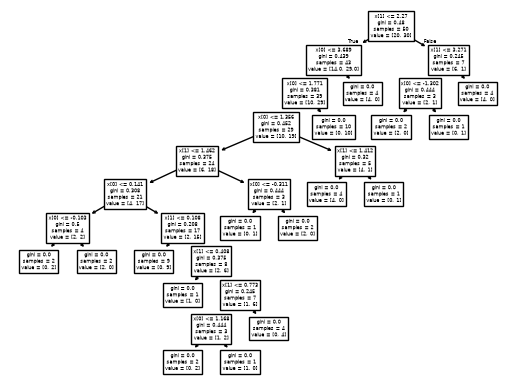

In [20]:
plot_tree(clf1)

[Text(0.5909090909090909, 0.9, 'x[1] <= -0.161\ngini = 0.493\nsamples = 50\nvalue = [22.0, 28.0]'),
 Text(0.36363636363636365, 0.7, 'x[0] <= 0.513\ngini = 0.278\nsamples = 24\nvalue = [20, 4]'),
 Text(0.4772727272727273, 0.8, 'True  '),
 Text(0.18181818181818182, 0.5, 'x[0] <= -0.073\ngini = 0.095\nsamples = 20\nvalue = [19, 1]'),
 Text(0.09090909090909091, 0.3, 'gini = 0.0\nsamples = 16\nvalue = [16, 0]'),
 Text(0.2727272727272727, 0.3, 'x[0] <= -0.035\ngini = 0.375\nsamples = 4\nvalue = [3, 1]'),
 Text(0.18181818181818182, 0.1, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.36363636363636365, 0.1, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.5454545454545454, 0.5, 'x[1] <= -1.494\ngini = 0.375\nsamples = 4\nvalue = [1, 3]'),
 Text(0.45454545454545453, 0.3, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.6363636363636364, 0.3, 'gini = 0.0\nsamples = 3\nvalue = [0, 3]'),
 Text(0.8181818181818182, 0.7, 'x[0] <= -0.963\ngini = 0.142\nsamples = 26\nvalue = [2, 24]'),
 Text

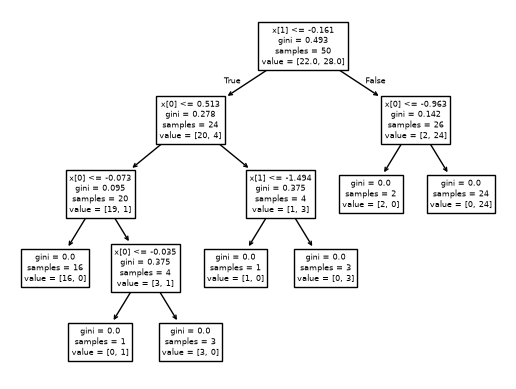

In [21]:
plot_tree(clf2)

[Text(0.640625, 0.9285714285714286, 'x[0] <= 0.149\ngini = 0.493\nsamples = 50\nvalue = [28.0, 22.0]'),
 Text(0.40625, 0.7857142857142857, 'x[1] <= -0.792\ngini = 0.394\nsamples = 37\nvalue = [27, 10]'),
 Text(0.5234375, 0.8571428571428572, 'True  '),
 Text(0.25, 0.6428571428571429, 'x[1] <= -1.858\ngini = 0.498\nsamples = 17\nvalue = [9, 8]'),
 Text(0.125, 0.5, 'x[1] <= -3.262\ngini = 0.219\nsamples = 8\nvalue = [7, 1]'),
 Text(0.0625, 0.35714285714285715, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.1875, 0.35714285714285715, 'gini = 0.0\nsamples = 7\nvalue = [7, 0]'),
 Text(0.375, 0.5, 'x[0] <= -1.637\ngini = 0.346\nsamples = 9\nvalue = [2, 7]'),
 Text(0.3125, 0.35714285714285715, 'gini = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.4375, 0.35714285714285715, 'x[1] <= -1.658\ngini = 0.219\nsamples = 8\nvalue = [1, 7]'),
 Text(0.375, 0.21428571428571427, 'x[1] <= -1.759\ngini = 0.444\nsamples = 3\nvalue = [1, 2]'),
 Text(0.3125, 0.07142857142857142, 'gini = 0.0\nsamples = 2\nva

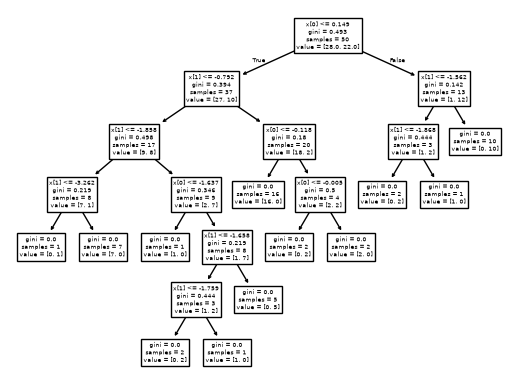

In [22]:
plot_tree(clf3)

In [23]:
clf1.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\COLLEGE DATA\College profile\Machine Learning\ML_Practice_with_python_code\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([1])

In [24]:
clf2.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\COLLEGE DATA\College profile\Machine Learning\ML_Practice_with_python_code\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [25]:
clf3.predict(np.array([-1.042498,	-0.064323]).reshape(1,2))

c:\COLLEGE DATA\College profile\Machine Learning\ML_Practice_with_python_code\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([0])

In [28]:
df.sample(10,replace=True)

,col1,col2,col3,col4,col5,target
16,-2.041923,1.086610,-0.790911,-1.072610,-1.640283,0
52,-2.008813,-0.806817,0.959523,1.898261,-1.843226,0
63,-1.388885,0.780849,0.056003,-1.470834,-0.799334,0
91,-0.930677,-0.149207,0.044283,0.085126,-0.340032,0
2,-1.857607,-0.413967,-0.616567,1.723643,-3.136818,0
2,-1.857607,-0.413967,-0.616567,1.723643,-3.136818,0
59,-0.819348,-0.483136,0.470825,-0.184791,-3.014304,0
66,-1.316372,-0.759369,-1.527646,1.086614,-1.161132,0
28,2.819802,0.135451,0.790587,-0.749297,-0.773117,1
67,-0.205558,2.695965,2.920606,1.413792,0.197280,1
